In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/adityajn105/flickr8k/captions.txt
/kaggle/input/datasets/adityajn105/flickr8k/Images/3226254560_2f8ac147ea.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/214543992_ce6c0d9f9b.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/2366643786_9c9a830db8.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/3368819708_0bfa0808f8.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/2190227737_6e0bde2623.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/2752809449_632cd991b3.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/3097776588_312932e438.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/1206506157_c7956accd5.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/1319634306_816f21677f.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/2465218087_fca77998c6.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/3351493005_6e5030f596.jpg
/kaggle/input/datasets/adityajn105/flickr8k/Images/2949337912_beba55698b.jpg
/kaggle/input/datase

📦 Section 1 — Environment Setup & Imports


In [2]:
!pip install -q nltk==3.8.1 rouge-score==0.1.2 evaluate==0.4.0

import os, math, json, random, time, zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

import nltk
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
nltk.download('wordnet', quiet=True)
nltk.download('punkt',   quiet=True)
nltk.download('omw-1.4', quiet=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {DEVICE}')
print(f'PyTorch : {torch.__version__}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.4/81.4 kB 6.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
textblob 0.19.0 requires nltk>=3.9, but you have nltk 3.8.1 which is incompatible.
Device  : cuda
PyTorch : 2.10.0+cu128


📂 Section 2 — Dataset Loading & Preprocessing


In [3]:
BASE_DIR     = Path('/kaggle/input/datasets/adityajn105/flickr8k')
IMAGE_DIR    = BASE_DIR / 'Images'
CAPTION_FILE = BASE_DIR / 'captions.txt'

df = pd.read_csv(CAPTION_FILE)
df.columns = ['image', 'caption']
df['caption'] = df['caption'].str.lower().str.strip()

print(f'Total lignes     : {len(df)}')
print(f'Images uniques   : {df["image"].nunique()}')
print(df.head(3))

Total lignes     : 40455
Images uniques   : 8091
                       image  \
0  1000268201_693b08cb0e.jpg   
1  1000268201_693b08cb0e.jpg   
2  1000268201_693b08cb0e.jpg   

                                             caption  
0  a child in a pink dress is climbing up a set o...  
1              a girl going into a wooden building .  
2   a little girl climbing into a wooden playhouse .  


In [4]:
unique_images = df['image'].unique()
np.random.shuffle(unique_images)

train_imgs = set(unique_images[:6000])
val_imgs   = set(unique_images[6000:7000])
test_imgs  = set(unique_images[7000:8000])

train_df = df[df['image'].isin(train_imgs)].reset_index(drop=True)
val_df   = df[df['image'].isin(val_imgs)].reset_index(drop=True)
test_df  = df[df['image'].isin(test_imgs)].reset_index(drop=True)

print(f'Train : {len(train_df)} | Val : {len(val_df)} | Test : {len(test_df)}')

Train : 30000 | Val : 5000 | Test : 5000


🖼️ Section 3 — Feature Extraction (VGGNet-16)


In [5]:
class VGGEncoder(nn.Module):
    """
    VGG-16 pré-entraîné sur ImageNet, poids gelés.
    use_fc=True  → vecteur global 4096-d  (NIC / Log Bilinear)
    use_fc=False → feature maps 14×14×512 (SAT attention)
    """
    def __init__(self, use_fc: bool = True):
        super().__init__()
        vgg = models.vgg16(pretrained=True)
        for p in vgg.parameters():
            p.requires_grad = False

        if use_fc:
            self.encoder = nn.Sequential(
                *list(vgg.features),
                vgg.avgpool,
                nn.Flatten(),
                vgg.classifier[0],   # 25088 → 4096
                vgg.classifier[1],   # ReLU
                vgg.classifier[2]    # Dropout
            )
            self.out_dim = 4096
        else:
            self.encoder = nn.Sequential(*list(vgg.features)[:-1])
            self.out_dim = 512

        self.use_fc = use_fc

    def forward(self, images):
        feat = self.encoder(images)
        if not self.use_fc:
            B, C, H, W = feat.shape
            feat = feat.permute(0, 2, 3, 1).contiguous().view(B, -1, C)
        return feat


IMG_TRANSFORM = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225])
])

print('VGGEncoder défini.')

VGGEncoder défini.


In [6]:
FEATURE_CACHE = Path('/kaggle/working/features_vgg16_fc.pt')

def cache_features(image_dir, df, encoder, transform, cache_path, batch_size=64):
    if cache_path.exists():
        print('Chargement depuis le cache…')
        return torch.load(cache_path)

    encoder.eval().to(DEVICE)
    unique_imgs = df['image'].unique()
    features    = {}

    for i in range(0, len(unique_imgs), batch_size):
        batch_names   = unique_imgs[i:i+batch_size]
        batch_tensors = []
        valid_names   = []

        for name in batch_names:
            img_path = image_dir / name
            if not img_path.exists():
                continue
            img = Image.open(img_path).convert('RGB')
            batch_tensors.append(transform(img))
            valid_names.append(name)

        if not batch_tensors:
            continue

        with torch.no_grad():
            batch = torch.stack(batch_tensors).to(DEVICE)
            feats = encoder(batch).cpu()

        for name, feat in zip(valid_names, feats):
            features[name] = feat

        if i % 640 == 0:
            print(f'  Traité {i}/{len(unique_imgs)}…')

    torch.save(features, cache_path)
    print(f'Features sauvegardées → {cache_path}')
    return features


encoder_fc     = VGGEncoder(use_fc=True)
image_features = cache_features(IMAGE_DIR, df, encoder_fc, IMG_TRANSFORM, FEATURE_CACHE)
print(f'Features chargées : {len(image_features)} images')

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 232MB/s]


  Traité 0/8091…
  Traité 640/8091…
  Traité 1280/8091…
  Traité 1920/8091…
  Traité 2560/8091…
  Traité 3200/8091…
  Traité 3840/8091…
  Traité 4480/8091…
  Traité 5120/8091…
  Traité 5760/8091…
  Traité 6400/8091…
  Traité 7040/8091…
  Traité 7680/8091…
Features sauvegardées → /kaggle/working/features_vgg16_fc.pt
Features chargées : 8091 images


📝 Section 4 — Vocabulary & Caption Preprocessing


In [7]:
MIN_FREQ = 5
PAD, SOS, EOS, UNK = '<PAD>', '<SOS>', '<EOS>', '<UNK>'

class Vocabulary:
    def __init__(self, min_freq=5):
        self.min_freq = min_freq
        self.word2idx = {PAD: 0, SOS: 1, EOS: 2, UNK: 3}
        self.idx2word = {v: k for k, v in self.word2idx.items()}

    def build(self, captions):
        counter = Counter()
        for cap in captions:
            counter.update(cap.split())
        for word, cnt in counter.items():
            if cnt >= self.min_freq and word not in self.word2idx:
                idx = len(self.word2idx)
                self.word2idx[word] = idx
                self.idx2word[idx]  = word
        print(f'Taille vocabulaire : {len(self.word2idx)}')

    def encode(self, caption, max_len=50):
        tokens = caption.split()[:max_len]
        ids = ([ self.word2idx[SOS] ]
             + [ self.word2idx.get(t, self.word2idx[UNK]) for t in tokens ]
             + [ self.word2idx[EOS] ])
        return ids

    def decode(self, ids):
        words = []
        for i in ids:
            w = self.idx2word.get(i, UNK)
            if w in (PAD, SOS): continue
            if w == EOS:        break
            words.append(w)
        return ' '.join(words)

    def __len__(self):
        return len(self.word2idx)


vocab = Vocabulary(MIN_FREQ)
vocab.build(train_df['caption'].tolist())

Taille vocabulaire : 2558


In [8]:
MAX_LEN = 50

class Flickr8kDataset(Dataset):
    def __init__(self, df, features, vocab, max_len=MAX_LEN):
        self.df       = df
        self.features = features
        self.vocab    = vocab
        self.max_len  = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        img_key = row['image']
        feat    = self.features[img_key]
        ids     = self.vocab.encode(row['caption'], self.max_len)
        pad_len = self.max_len + 2 - len(ids)
        ids     = ids + [self.vocab.word2idx[PAD]] * pad_len
        return feat, torch.tensor(ids, dtype=torch.long)


train_set = Flickr8kDataset(train_df, image_features, vocab)
val_set   = Flickr8kDataset(val_df,   image_features, vocab)
test_set  = Flickr8kDataset(test_df,  image_features, vocab)

BATCH        = 64
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f'Batches — Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}')

Batches — Train: 469 | Val: 79 | Test: 79


🤖 Section 5 — Google NIC (Vinyals et al., 2014)


In [9]:
class NIC_Decoder(nn.Module):
    """
    LSTM caption decoder — Google NIC (Vinyals et al., 2014).
    Le feature CNN est projeté comme état caché initial (h0, c0).
    L'image est injectée UNE SEULE FOIS à t=0.
    """
    def __init__(self, vocab_size, embed_dim, hidden_dim, feat_dim, dropout=0.5):
        super().__init__()
        self.embed      = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm       = nn.LSTMCell(embed_dim, hidden_dim)
        self.init_h     = nn.Linear(feat_dim, hidden_dim)
        self.init_c     = nn.Linear(feat_dim, hidden_dim)
        self.fc_out     = nn.Linear(hidden_dim, vocab_size)
        self.dropout    = nn.Dropout(dropout)
        self.hidden_dim = hidden_dim

    def forward(self, features, captions):
        """
        features : (B, feat_dim)
        captions : (B, T)
        Retourne : logits (B, T-1, vocab_size)
        """
        B, T       = captions.shape
        embeddings = self.dropout(self.embed(captions))       # (B, T, E)
        h = torch.tanh(self.init_h(self.dropout(features)))  # (B, H)
        c = torch.tanh(self.init_c(self.dropout(features)))  # (B, H)

        logits = []
        for t in range(T - 1):
            inp  = embeddings[:, t, :]
            h, c = self.lstm(inp, (h, c))
            out  = self.fc_out(self.dropout(h))               # (B, V)
            logits.append(out)

        return torch.stack(logits, dim=1)                     # (B, T-1, V)

    @torch.no_grad()
    def generate(self, feature, vocab, max_len=50):
        """Greedy decoding."""
        h = torch.tanh(self.init_h(feature.unsqueeze(0)))
        c = torch.tanh(self.init_c(feature.unsqueeze(0)))
        word_id = torch.tensor([vocab.word2idx[SOS]], device=DEVICE)
        result  = []
        for _ in range(max_len):
            emb     = self.embed(word_id)
            h, c    = self.lstm(emb, (h, c))
            word_id = self.fc_out(h).argmax(dim=-1)
            w = vocab.idx2word[word_id.item()]
            if w == EOS: break
            result.append(w)
        return ' '.join(result)


EMBED_DIM  = 256
HIDDEN_DIM = 512
FEAT_DIM   = 4096

nic_model = NIC_Decoder(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    feat_dim=FEAT_DIM
).to(DEVICE)

print(f'Paramètres NIC : {sum(p.numel() for p in nic_model.parameters()):,}')
print(nic_model)

Paramètres NIC : 7,739,390
NIC_Decoder(
  (embed): Embedding(2558, 256, padding_idx=0)
  (lstm): LSTMCell(256, 512)
  (init_h): Linear(in_features=4096, out_features=512, bias=True)
  (init_c): Linear(in_features=4096, out_features=512, bias=True)
  (fc_out): Linear(in_features=512, out_features=2558, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)


🔗 Section 6 — Log Bilinear (Kiros et al., 2014a)


In [10]:
class LogBilinearDecoder(nn.Module):
    """
    Modèle log-bilinéaire multimodal — Kiros et al. (2014a).

    À chaque step t :
        p(w_t) ∝ exp( (C·ctx + W_I·v)ᵀ · E[w_t] )

    ctx  = fenêtre de context_size mots précédents (embeddings)
    v    = feature image (injecté à CHAQUE step)
    E    = matrice d'embedding partagée entrée/sortie
    """
    def __init__(self, vocab_size, embed_dim, feat_dim,
                 context_size=3, dropout=0.5):
        super().__init__()
        self.context_size = context_size
        self.embed_dim    = embed_dim
        self.embed        = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.C            = nn.Linear(context_size * embed_dim, embed_dim, bias=False)
        self.W_img        = nn.Linear(feat_dim, embed_dim, bias=True)
        self.dropout      = nn.Dropout(dropout)
        self.vocab_size   = vocab_size

    def forward(self, features, captions):
        """
        features : (B, feat_dim)
        captions : (B, T)
        Retourne : logits (B, T-1, vocab_size)
        """
        B, T     = captions.shape
        emb      = self.dropout(self.embed(captions))    # (B, T, E)
        img_bias = self.W_img(self.dropout(features))    # (B, E)

        logits = []
        for t in range(1, T):
            start = max(0, t - self.context_size)
            ctx   = emb[:, start:t, :]                   # (B, ≤C, E)
            pad   = self.context_size - ctx.shape[1]
            if pad > 0:
                ctx = F.pad(ctx, (0, 0, pad, 0))
            ctx_flat = ctx.reshape(B, -1)                # (B, C*E)
            h        = self.C(ctx_flat) + img_bias       # (B, E)
            score    = h @ self.embed.weight.t()          # (B, V)
            logits.append(score)

        return torch.stack(logits, dim=1)                 # (B, T-1, V)

    @torch.no_grad()
    def generate(self, feature, vocab, max_len=50):
        img_bias  = self.W_img(feature.unsqueeze(0))
        generated = [vocab.word2idx[SOS]]
        result    = []
        for _ in range(max_len):
            ids_t    = torch.tensor([generated], device=DEVICE)
            emb_t    = self.embed(ids_t)
            start    = max(0, len(generated) - self.context_size)
            ctx      = emb_t[:, start:, :]
            pad      = self.context_size - ctx.shape[1]
            if pad > 0:
                ctx  = F.pad(ctx, (0, 0, pad, 0))
            ctx_flat = ctx.reshape(1, -1)
            h        = self.C(ctx_flat) + img_bias
            word_id  = (h @ self.embed.weight.t()).argmax(dim=-1).item()
            w = vocab.idx2word[word_id]
            if w == EOS: break
            result.append(w)
            generated.append(word_id)
        return ' '.join(result)


lb_model = LogBilinearDecoder(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    feat_dim=FEAT_DIM,
    context_size=3
).to(DEVICE)

print(f'Paramètres Log Bilinear : {sum(p.numel() for p in lb_model.parameters()):,}')
print(lb_model)

Paramètres Log Bilinear : 1,900,288
LogBilinearDecoder(
  (embed): Embedding(2558, 256, padding_idx=0)
  (C): Linear(in_features=768, out_features=256, bias=False)
  (W_img): Linear(in_features=4096, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)


🏋️ Section 7 — Training Loop avec Early Stopping


In [11]:
def token_accuracy(logits, targets, pad_idx=0):
    """Accuracy token-level, ignore les positions PAD."""
    preds   = logits.argmax(dim=-1)
    mask    = targets[:, 1:] != pad_idx
    correct = (preds == targets[:, 1:]) & mask
    return correct.sum().item() / mask.sum().item()


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, total_acc, n = 0., 0., 0
    for features, captions in loader:
        features = features.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)

        optimizer.zero_grad()
        logits   = model(features, captions)
        B, T1, V = logits.shape
        loss = criterion(logits.reshape(B*T1, V),
                         captions[:, 1:].reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()

        total_loss += loss.item()
        total_acc  += token_accuracy(logits, captions)
        n          += 1

    return total_loss / n, total_acc / n


@torch.no_grad()
def evaluate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, total_acc, n = 0., 0., 0
    for features, captions in loader:
        features = features.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)
        logits   = model(features, captions)
        B, T1, V = logits.shape
        loss = criterion(logits.reshape(B*T1, V),
                         captions[:, 1:].reshape(-1))
        total_loss += loss.item()
        total_acc  += token_accuracy(logits, captions)
        n          += 1

    return total_loss / n, total_acc / n


def training_loop(model, train_loader, val_loader,
                  epochs=50,
                  lr=4e-4,
                  label='Model',
                  device=DEVICE,
                  patience=7,
                  min_delta=1e-4):
    """
    Entraînement avec :
      - 50 epochs maximum
      - ReduceLROnPlateau  : divise lr par 2 si val_loss ne baisse plus après 3 epochs
      - Early stopping     : arrêt si val_loss ne s'améliore plus après `patience` epochs
      - Sauvegarde du meilleur modèle
    """
    criterion = nn.CrossEntropyLoss(ignore_index=0)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=3,
    )

    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc':  [], 'val_acc':  []
    }

    best_val_loss     = float('inf')
    best_path         = f'/kaggle/working/{label}_best.pt'
    epochs_no_improve = 0

    print(f'\n{"="*65}')
    print(f'  {label}  |  max {epochs} epochs  |  patience={patience}  |  lr={lr}')
    print(f'{"="*65}')

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
        vl_loss, vl_acc = evaluate_epoch(model, val_loader,   criterion, device)

        scheduler.step(vl_loss)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(vl_acc)

        # ── Meilleur modèle & compteur early stopping ───────────────────────
        if vl_loss < best_val_loss - min_delta:
            best_val_loss     = vl_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_path)
            tag = '✔ best saved'
        else:
            epochs_no_improve += 1
            tag = f'no improve ({epochs_no_improve}/{patience})'

        elapsed = time.time() - t0
        print(f'[{label}] Ep {epoch:03d}/{epochs} | '
              f'Train Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f} | '
              f'Val Loss: {vl_loss:.4f}  Acc: {vl_acc:.4f} | '
              f'{elapsed:.1f}s | {tag}')

        # ── Early stopping ──────────────────────────────────────────────────
        if epochs_no_improve >= patience:
            print(f'\n⚠  Early stopping à l\'epoch {epoch} '
                  f'(pas d\'amélioration depuis {patience} epochs).')
            break

    # ── Rechargement du meilleur checkpoint ─────────────────────────────────
    model.load_state_dict(torch.load(best_path))
    print(f'\n✔ Meilleur modèle rechargé — Val Loss : {best_val_loss:.4f}')
    print(f'  Epochs effectuées : {epoch}/{epochs}')

    return history, epoch

In [12]:
# ── Lancer l'entraînement ────────────────────────────────────────────────────
nic_history, nic_stopped = training_loop(
    nic_model, train_loader, val_loader,
    epochs=50, lr=4e-4, label='NIC',
    patience=5, min_delta=1e-4
)

lb_history, lb_stopped = training_loop(
    lb_model, train_loader, val_loader,
    epochs=50, lr=4e-4, label='LogBilinear',
    patience=5, min_delta=1e-4
)


  NIC  |  max 50 epochs  |  patience=5  |  lr=0.0004
[NIC] Ep 001/50 | Train Loss: 4.0764  Acc: 0.3015 | Val Loss: 3.3961  Acc: 0.3586 | 21.6s | ✔ best saved
[NIC] Ep 002/50 | Train Loss: 3.3598  Acc: 0.3585 | Val Loss: 3.0876  Acc: 0.3854 | 21.2s | ✔ best saved
[NIC] Ep 003/50 | Train Loss: 3.1122  Acc: 0.3790 | Val Loss: 2.9243  Acc: 0.4012 | 21.0s | ✔ best saved
[NIC] Ep 004/50 | Train Loss: 2.9568  Acc: 0.3933 | Val Loss: 2.8308  Acc: 0.4112 | 21.0s | ✔ best saved
[NIC] Ep 005/50 | Train Loss: 2.8456  Acc: 0.4050 | Val Loss: 2.7642  Acc: 0.4158 | 21.4s | ✔ best saved
[NIC] Ep 006/50 | Train Loss: 2.7579  Acc: 0.4146 | Val Loss: 2.7159  Acc: 0.4219 | 21.2s | ✔ best saved
[NIC] Ep 007/50 | Train Loss: 2.6869  Acc: 0.4221 | Val Loss: 2.6805  Acc: 0.4250 | 21.4s | ✔ best saved
[NIC] Ep 008/50 | Train Loss: 2.6233  Acc: 0.4288 | Val Loss: 2.6551  Acc: 0.4298 | 21.4s | ✔ best saved
[NIC] Ep 009/50 | Train Loss: 2.5697  Acc: 0.4341 | Val Loss: 2.6369  Acc: 0.4304 | 20.8s | ✔ best saved
[

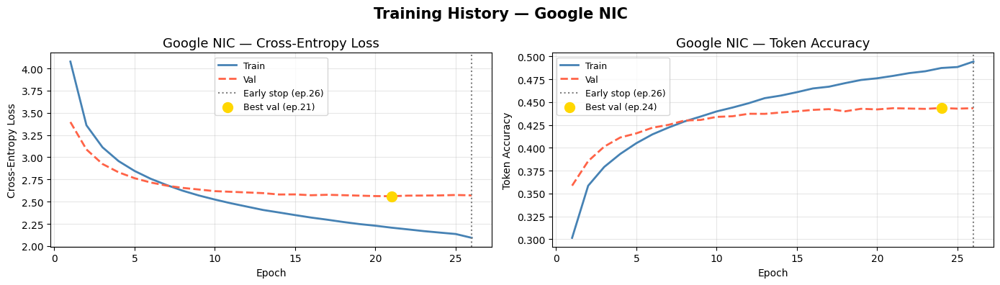

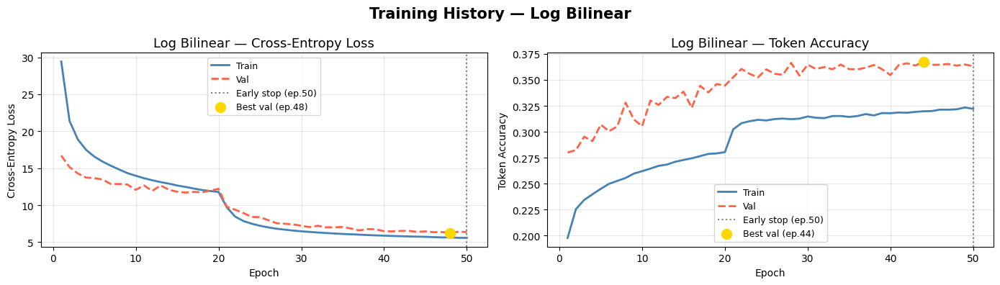

In [13]:
# ── Courbes de training ──────────────────────────────────────────────────────
def plot_history(history, label, stopped_at=None):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    pairs = [
        ('train_loss', 'val_loss', 'Cross-Entropy Loss'),
        ('train_acc',  'val_acc',  'Token Accuracy'),
    ]

    for ax, (tr_key, vl_key, title) in zip(axes, pairs):
        ax.plot(epochs, history[tr_key], 'steelblue', linewidth=2, label='Train')
        ax.plot(epochs, history[vl_key], 'tomato',    linewidth=2,
                linestyle='--', label='Val')

        if stopped_at:
            ax.axvline(x=stopped_at, color='gray', linestyle=':',
                       linewidth=1.5, label=f'Early stop (ep.{stopped_at})')

        # Point meilleur val
        if 'loss' in vl_key:
            best_ep  = int(np.argmin(history[vl_key])) + 1
            best_val = min(history[vl_key])
        else:
            best_ep  = int(np.argmax(history[vl_key])) + 1
            best_val = max(history[vl_key])

        ax.scatter(best_ep, best_val, color='gold', s=100,
                   zorder=5, label=f'Best val (ep.{best_ep})')

        ax.set_title(f'{label} — {title}', fontsize=13)
        ax.set_xlabel('Epoch')
        ax.set_ylabel(title)
        ax.legend(fontsize=9)
        ax.grid(alpha=0.3)

    plt.suptitle(f'Training History — {label}', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/{label}_curves.png', dpi=150)
    plt.show()


plot_history(nic_history, 'Google NIC',   stopped_at=nic_stopped)
plot_history(lb_history,  'Log Bilinear', stopped_at=lb_stopped)

📊 Section 8 — Évaluation BLEU & METEOR


In [14]:
!pip install --upgrade nltk
# --- DÉBUT DU HACK POUR CONTOURNER L'ERREUR NLTK SANS REDÉMARRER ---
import fractions
import nltk.translate.bleu_score

# On crée une fausse classe Fraction qui ignore l'argument '_normalize'
class CompatibleFraction(fractions.Fraction):
    def __new__(cls, numerator=0, denominator=None, **kwargs):
        # On supprime '_normalize' s'il est présent dans kwargs
        kwargs.pop('_normalize', None)
        return super(CompatibleFraction, cls).__new__(cls, numerator, denominator, **kwargs)

# On remplace la Fraction utilisée par NLTK par notre version compatible
nltk.translate.bleu_score.Fraction = CompatibleFraction
def build_references(df):
    refs = {}
    for _, row in df.iterrows():
        key = row['image']
        cap = row['caption'].split()
        refs.setdefault(key, []).append(cap)
    return refs

test_refs = build_references(test_df)


def evaluate_model(model, test_refs, image_features, vocab, device=DEVICE):
    model.eval()
    hypotheses = []
    references  = []

    for img_name, refs in test_refs.items():
        if img_name not in image_features:
            continue
        feat = image_features[img_name].to(device)
        with torch.no_grad():
            caption = model.generate(feat, vocab)
        hypotheses.append(caption.split())
        references.append(refs)

    bleu1 = corpus_bleu(references, hypotheses, weights=(1,    0,    0,    0   ))
    bleu2 = corpus_bleu(references, hypotheses, weights=(0.5,  0.5,  0,    0   ))
    bleu3 = corpus_bleu(references, hypotheses, weights=(1/3,  1/3,  1/3,  0   ))
    bleu4 = corpus_bleu(references, hypotheses, weights=(0.25, 0.25, 0.25, 0.25))

    meteor_scores = [
        meteor_score(refs, hyp)
        for refs, hyp in zip(references, hypotheses)
    ]
    avg_meteor = np.mean(meteor_scores)

    return {
        'BLEU-1': round(bleu1 * 100, 2),
        'BLEU-2': round(bleu2 * 100, 2),
        'BLEU-3': round(bleu3 * 100, 2),
        'BLEU-4': round(bleu4 * 100, 2),
        'METEOR': round(avg_meteor * 100, 2),
    }


print('Calcul métriques NIC…')
nic_metrics = evaluate_model(nic_model, test_refs, image_features, vocab)
print('NIC :', nic_metrics)

print('Calcul métriques Log Bilinear…')
lb_metrics  = evaluate_model(lb_model,  test_refs, image_features, vocab)
print('LB  :', lb_metrics)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 19.8 MB/s eta 0:00:00
  Attempting uninstall: nltk
    Found existing installation: nltk 3.8.1
    Uninstalling nltk-3.8.1:
      Successfully uninstalled nltk-3.8.1
Calcul métriques NIC…
NIC : {'BLEU-1': 60.65, 'BLEU-2': 42.01, 'BLEU-3': 32.65, 'BLEU-4': 26.02, 'METEOR': np.float64(41.43)}
Calcul métriques Log Bilinear…
LB  : {'BLEU-1': 27.41, 'BLEU-2': 16.67, 'BLEU-3': 12.75, 'BLEU-4': 10.47, 'METEOR': np.float64(28.48)}


📋 Section 9 — Comparaison avec les valeurs de l'article 2015

In [15]:
# ── Valeurs officielles du papier Xu et al. 2015 — Flickr8k ─────────────────
paper_2015 = {
    'Google NIC (papier 2015)':   {'BLEU-1': 63.0, 'BLEU-2': 41.0, 'BLEU-3': 27.0, 'BLEU-4': None,  'METEOR': None},
    'Log Bilinear (papier 2015)': {'BLEU-1': 65.6, 'BLEU-2': 42.4, 'BLEU-3': 27.7, 'BLEU-4': 17.7,  'METEOR': 17.31},
}

our_results = {
    'Google NIC (nous)':          nic_metrics,
    'Log Bilinear (nous)':        lb_metrics,
}

# ── Tableau comparatif ───────────────────────────────────────────────────────
df_paper = pd.DataFrame(paper_2015).T
df_ours  = pd.DataFrame(our_results).T

print('\n══ Valeurs du papier 2015 ══')
print(df_paper.fillna('—').to_string())

print('\n══ Nos résultats ══')
print(df_ours.to_string())

# ── Tableau différence ───────────────────────────────────────────────────────
print('\n══ Différence (nos résultats - papier 2015) ══')
metrics_common = ['BLEU-1', 'BLEU-2', 'BLEU-3']

diff_nic = {
    m: round(nic_metrics[m] - paper_2015['Google NIC (papier 2015)'][m], 2)
    for m in metrics_common
}
diff_lb = {
    m: round(lb_metrics[m] - paper_2015['Log Bilinear (papier 2015)'][m], 2)
    for m in metrics_common
    if paper_2015['Log Bilinear (papier 2015)'][m] is not None
}
diff_lb['BLEU-4'] = round(lb_metrics['BLEU-4'] - 17.7,  2)
diff_lb['METEOR'] = round(lb_metrics['METEOR']  - 17.31, 2)

df_diff = pd.DataFrame({
    'Google NIC':   diff_nic,
    'Log Bilinear': diff_lb,
}).T
df_diff.index.name = 'Modèle'
print(df_diff.to_string())
print('\n(+ = au dessus du papier | - = en dessous du papier)')


══ Valeurs du papier 2015 ══
                            BLEU-1  BLEU-2  BLEU-3 BLEU-4 METEOR
Google NIC (papier 2015)      63.0    41.0    27.0      —      —
Log Bilinear (papier 2015)    65.6    42.4    27.7   17.7  17.31

══ Nos résultats ══
                     BLEU-1  BLEU-2  BLEU-3  BLEU-4  METEOR
Google NIC (nous)     60.65   42.01   32.65   26.02   41.43
Log Bilinear (nous)   27.41   16.67   12.75   10.47   28.48

══ Différence (nos résultats - papier 2015) ══
              BLEU-1  BLEU-2  BLEU-3  BLEU-4  METEOR
Modèle                                              
Google NIC     -2.35    1.01    5.65     NaN     NaN
Log Bilinear  -38.19  -25.73  -14.95   -7.23   11.17

(+ = au dessus du papier | - = en dessous du papier)


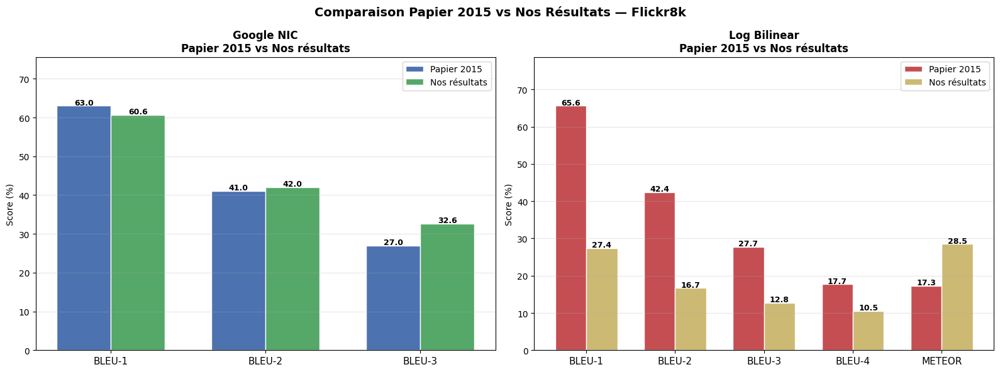

In [16]:
# ── Graphique côte à côte papier vs nous ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
metrics_plot = ['BLEU-1', 'BLEU-2', 'BLEU-3']
x     = np.arange(len(metrics_plot))
width = 0.35

# --- Google NIC ---
ax = axes[0]
paper_vals = [paper_2015['Google NIC (papier 2015)'][m] for m in metrics_plot]
our_vals   = [nic_metrics[m] for m in metrics_plot]

b1 = ax.bar(x - width/2, paper_vals, width, label='Papier 2015',
            color='#4C72B0', edgecolor='white')
b2 = ax.bar(x + width/2, our_vals,   width, label='Nos résultats',
            color='#55A868', edgecolor='white')

for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f}', ha='center', fontsize=9, fontweight='bold')
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f}', ha='center', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(metrics_plot, fontsize=11)
ax.set_ylabel('Score (%)')
ax.set_title('Google NIC\nPapier 2015 vs Nos résultats', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, max(paper_vals + our_vals) * 1.2)

# --- Log Bilinear ---
ax = axes[1]
metrics_lb    = ['BLEU-1', 'BLEU-2', 'BLEU-3', 'BLEU-4', 'METEOR']
x2            = np.arange(len(metrics_lb))          # ← défini AVANT d'être utilisé
paper_vals_lb = [paper_2015['Log Bilinear (papier 2015)'][m] for m in metrics_lb]
our_vals_lb   = [lb_metrics[m] for m in metrics_lb]

b3 = ax.bar(x2 - width/2, paper_vals_lb, width, label='Papier 2015',
            color='#C44E52', edgecolor='white')
b4 = ax.bar(x2 + width/2, our_vals_lb,   width, label='Nos résultats',
            color='#CCB974', edgecolor='white')

for bar in b3:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f}', ha='center', fontsize=9, fontweight='bold')
for bar in b4:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f}', ha='center', fontsize=9, fontweight='bold')

ax.set_xticks(x2)
ax.set_xticklabels(metrics_lb, fontsize=11)
ax.set_ylabel('Score (%)')
ax.set_title('Log Bilinear\nPapier 2015 vs Nos résultats', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, max(paper_vals_lb + our_vals_lb) * 1.2)

plt.suptitle('Comparaison Papier 2015 vs Nos Résultats — Flickr8k',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/comparaison_2015_vs_nous.png', dpi=150)
plt.show()

🔍 Section 10 — Analyse d'erreurs


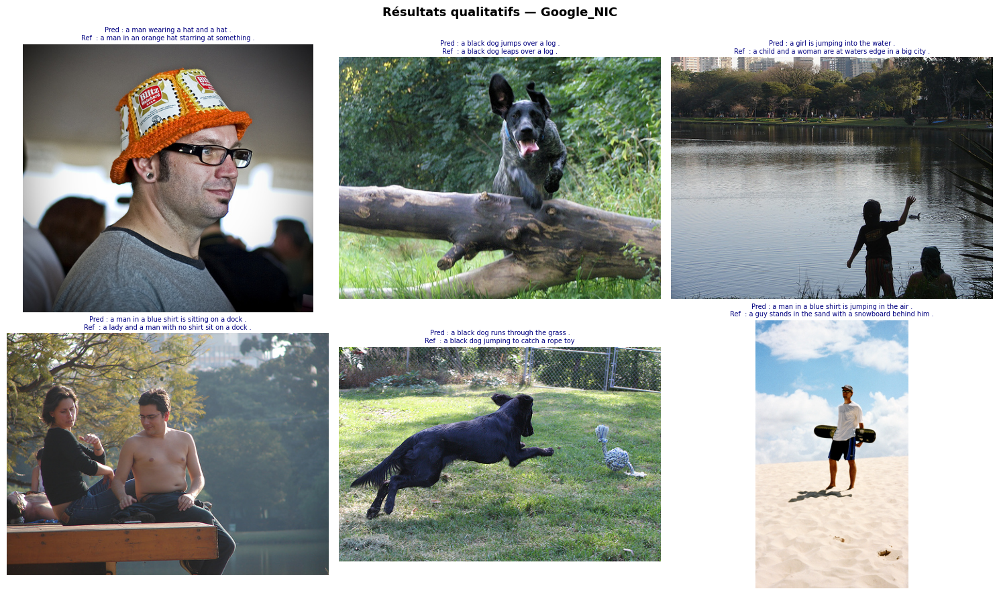

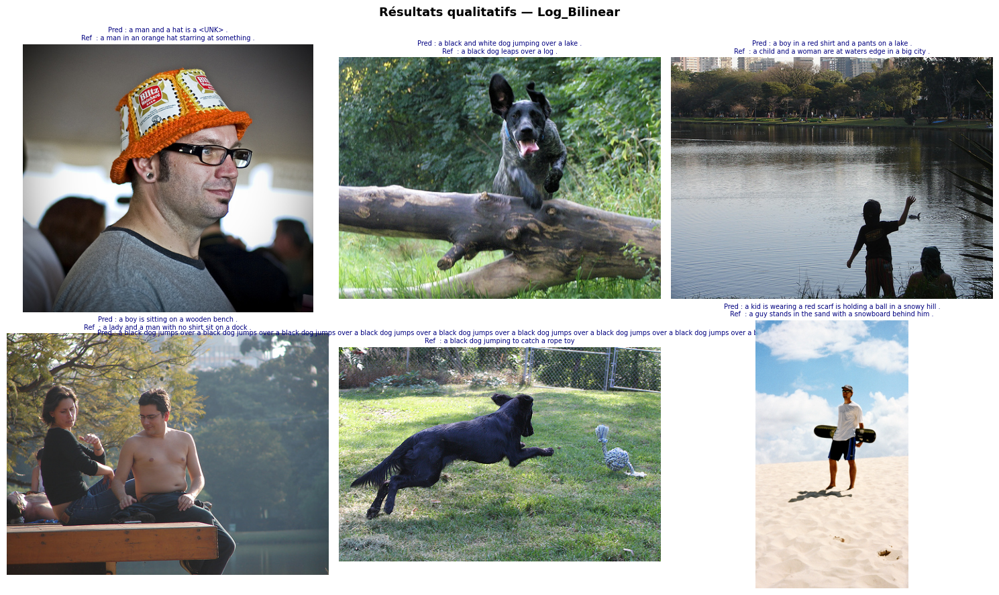

In [17]:
def show_predictions(model, model_name, test_refs, image_features,
                     image_dir, vocab, n=6, device=DEVICE):
    model.eval()
    img_names = list(test_refs.keys())[:n]
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.flatten()

    for ax, img_name in zip(axes, img_names):
        img_path = image_dir / img_name
        if not img_path.exists():
            continue
        feat = image_features.get(img_name)
        if feat is None:
            continue
        with torch.no_grad():
            pred = model.generate(feat.to(device), vocab)

        ref_sample = ' '.join(test_refs[img_name][0])
        ax.imshow(Image.open(img_path).convert('RGB'))
        ax.set_title(f'Pred : {pred}\nRef  : {ref_sample}',
                     fontsize=7, color='navy', wrap=True)
        ax.axis('off')

    plt.suptitle(f'Résultats qualitatifs — {model_name}',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/{model_name}_qualitative.png', dpi=150)
    plt.show()


show_predictions(nic_model, 'Google_NIC',   test_refs, image_features, IMAGE_DIR, vocab)
show_predictions(lb_model,  'Log_Bilinear', test_refs, image_features, IMAGE_DIR, vocab)

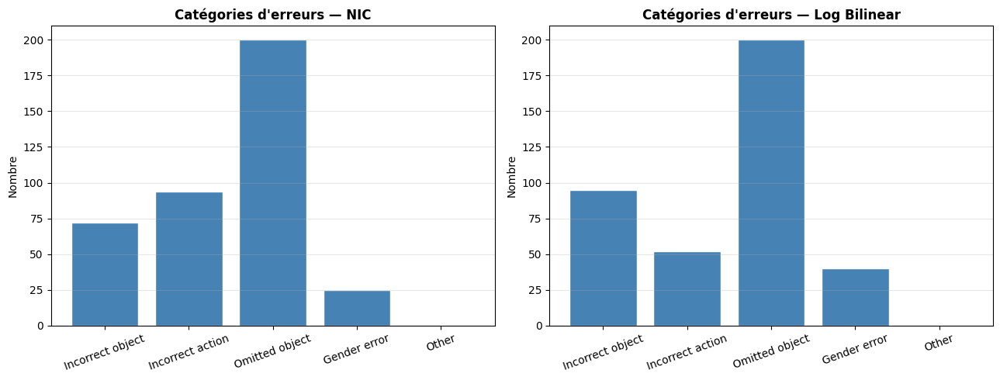

Erreurs NIC : {'Incorrect object': 72, 'Incorrect action': 94, 'Omitted object': 200, 'Gender error': 25, 'Other': 0}
Erreurs LB  : {'Incorrect object': 95, 'Incorrect action': 52, 'Omitted object': 200, 'Gender error': 40, 'Other': 0}


In [18]:
def categorize_errors(model, test_refs, image_features, vocab,
                      n_samples=200, device=DEVICE):
    model.eval()
    categories = {
        'Incorrect object': 0,
        'Incorrect action': 0,
        'Omitted object':   0,
        'Gender error':     0,
        'Other':            0,
    }
    action_words = {'running','jumping','sitting','standing','walking',
                    'playing','holding','riding','swimming','climbing'}
    gender_words = {'man','woman','boy','girl','male','female','he','she'}

    for img_name in list(test_refs.keys())[:n_samples]:
        feat = image_features.get(img_name)
        if feat is None:
            continue
        with torch.no_grad():
            pred = model.generate(feat.to(device), vocab)

        pred_set  = set(pred.split())
        ref_words = set(w for ref in test_refs[img_name] for w in ref)
        wrong     = pred_set - ref_words
        missing   = ref_words - pred_set

        if wrong & action_words:
            categories['Incorrect action'] += 1
        elif wrong & gender_words:
            categories['Gender error'] += 1
        elif wrong - action_words - gender_words:
            categories['Incorrect object'] += 1
        if missing - action_words - gender_words:
            categories['Omitted object'] += 1
        elif not (wrong | missing):
            pass
        else:
            categories['Other'] += 1

    return categories


nic_errors = categorize_errors(nic_model, test_refs, image_features, vocab)
lb_errors  = categorize_errors(lb_model,  test_refs, image_features, vocab)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (errors, name) in zip(axes, [(nic_errors,'NIC'), (lb_errors,'Log Bilinear')]):
    ax.bar(errors.keys(), errors.values(), color='steelblue', edgecolor='white')
    ax.set_title(f"Catégories d'erreurs — {name}", fontweight='bold')
    ax.set_ylabel('Nombre')
    ax.tick_params(axis='x', rotation=20)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/error_analysis.png', dpi=150)
plt.show()

print('Erreurs NIC :', nic_errors)
print('Erreurs LB  :', lb_errors)

🏁 Section 11 — Résumé des architectures & Conclusion


In [19]:
arch_data = {
    'Aspect': [
        'Encodeur', 'Décodeur', 'Injection image',
        'Attention', 'Objectif',
        'Force principale', 'Faiblesse principale'
    ],
    'Google NIC': [
        'VGG-16 (FC 4096-d)',
        'LSTM (LSTMCell)',
        'État caché initial t=0 uniquement',
        'Aucune',
        'Cross-entropy (teacher forcing)',
        'Simple, rapide, end-to-end',
        'Contexte image perdu après t=0'
    ],
    'Log Bilinear': [
        'VGG-16 (FC 4096-d)',
        'LM log-bilinéaire (sans RNN)',
        'Biais additif à chaque step',
        'Aucune',
        'Cross-entropy',
        'Image toujours présente, rapide',
        'Pas de mémoire temporelle'
    ],
    'Soft Attention (SAT)': [
        'VGG-16 (conv 14×14×512)',
        'LSTM + MLP attention',
        'Vecteur de contexte dynamique',
        'Soft / déterministe',
        'Cross-entropy + régul. doublement stochastique',
        'Spatiallement conscient, interprétable',
        'Plus complexe, entraînement plus lent'
    ],
}

df_arch = pd.DataFrame(arch_data).set_index('Aspect')
print(df_arch.to_string())

                                             Google NIC                     Log Bilinear                            Soft Attention (SAT)
Aspect                                                                                                                                  
Encodeur                             VGG-16 (FC 4096-d)               VGG-16 (FC 4096-d)                         VGG-16 (conv 14×14×512)
Décodeur                                LSTM (LSTMCell)     LM log-bilinéaire (sans RNN)                            LSTM + MLP attention
Injection image       État caché initial t=0 uniquement      Biais additif à chaque step                   Vecteur de contexte dynamique
Attention                                        Aucune                           Aucune                             Soft / déterministe
Objectif                Cross-entropy (teacher forcing)                    Cross-entropy  Cross-entropy + régul. doublement stochastique
Force principale             Simple, rapi

In [20]:
print('\n' + '='*65)
print('   RÉSUMÉ FINAL — Flickr8k  (Ahmed Fekih)')
print('='*65)

for name, metrics in [('Google NIC',   nic_metrics),
                       ('Log Bilinear', lb_metrics)]:
    print(f'\n{name}')
    for k, v in metrics.items():
        print(f'  {k:10s}: {v:.2f}')

print(f'\n  Epochs NIC         : {nic_stopped}')
print(f'  Epochs Log Bilinear: {lb_stopped}')

print('\n[Référence — Xu et al., 2015 — Flickr8k]')
print('  NIC          : BLEU-1=63.0 | BLEU-2=41.0 | BLEU-3=27.0')
print('  Log Bilinear : BLEU-1=65.6 | BLEU-2=42.4 | BLEU-3=27.7 | BLEU-4=17.7 | METEOR=17.31')
print('='*65)


   RÉSUMÉ FINAL — Flickr8k  (Ahmed Fekih)

Google NIC
  BLEU-1    : 60.65
  BLEU-2    : 42.01
  BLEU-3    : 32.65
  BLEU-4    : 26.02
  METEOR    : 41.43

Log Bilinear
  BLEU-1    : 27.41
  BLEU-2    : 16.67
  BLEU-3    : 12.75
  BLEU-4    : 10.47
  METEOR    : 28.48

  Epochs NIC         : 26
  Epochs Log Bilinear: 50

[Référence — Xu et al., 2015 — Flickr8k]
  NIC          : BLEU-1=63.0 | BLEU-2=41.0 | BLEU-3=27.0
  Log Bilinear : BLEU-1=65.6 | BLEU-2=42.4 | BLEU-3=27.7 | BLEU-4=17.7 | METEOR=17.31


📰 Partie Article 2023 — Liu & Brailsford


Section A — Analyse d'erreurs (10 catégories comme dans le papier)


In [21]:
# ════════════════════════════════════════════════════════════════════════════
#  ARTICLE 2023 — Liu & Brailsford
#  PARTIE 1 : Analyse d'erreurs (10 catégories)
# ════════════════════════════════════════════════════════════════════════════

import spacy
# !python -m spacy download en_core_web_sm
nlp = spacy.load('en_core_web_sm')

# ── 10 catégories exactes du papier 2023 ────────────────────────────────────
ERROR_CATEGORIES = [
    'Wrong object',
    'Incorrect action',
    'Missed object',
    'Object property',
    'Gender detection',
    'Scene recognition',
    'Complicated background',
    'Phrase repeat',        # erreurs syntaxiques
    'Object relation',
    'Facial emotion',
]

action_words  = {'run','jump','sit','stand','walk','play','hold',
                 'ride','swim','climb','throw','catch','eat','drink',
                 'running','jumping','sitting','standing','walking',
                 'playing','holding','riding','swimming','climbing'}

gender_words  = {'man','woman','boy','girl','male','female',
                 'he','she','his','her','guy','lady','gentleman'}

scene_words   = {'beach','park','street','field','forest','mountain',
                 'kitchen','room','court','track','road','pool','lake'}

property_words = {'red','blue','green','white','black','yellow','large',
                  'small','big','little','tall','short','old','young'}

emotion_words  = {'happy','sad','angry','surprised','scared',
                  'smiling','laughing','crying'}

relation_words = {'next','behind','front','above','below','between',
                  'beside','near','on','under','over','with'}


def analyze_errors_2023(model, test_refs, image_features, vocab,
                        n_samples=143, device=DEVICE):
    """
    Reproduit l'analyse manuelle de Liu & Brailsford (2023).
    143 cas examinés (comme dans le papier).
    Retourne le compte par catégorie d'erreur.
    """
    model.eval()
    counts = {cat: 0 for cat in ERROR_CATEGORIES}
    results = []   # pour inspection manuelle

    for img_name in list(test_refs.keys())[:n_samples]:
        feat = image_features.get(img_name)
        if feat is None:
            continue

        with torch.no_grad():
            pred = model.generate(feat.to(device), vocab)

        pred_words = set(pred.split())
        ref_words  = set(w for ref in test_refs[img_name] for w in ref)
        wrong      = pred_words - ref_words
        missing    = ref_words  - pred_words

        # Détection phrase répétée (syntaxique)
        pred_tokens = pred.split()
        has_repeat  = any(
            pred_tokens[i] == pred_tokens[i+1]
            for i in range(len(pred_tokens)-1)
        )

        errors_found = []

        if wrong & action_words:
            counts['Incorrect action'] += 1
            errors_found.append('Incorrect action')

        if wrong & gender_words or missing & gender_words:
            counts['Gender detection'] += 1
            errors_found.append('Gender detection')

        if wrong & scene_words:
            counts['Scene recognition'] += 1
            errors_found.append('Scene recognition')

        if wrong & property_words:
            counts['Object property'] += 1
            errors_found.append('Object property')

        if wrong & emotion_words:
            counts['Facial emotion'] += 1
            errors_found.append('Facial emotion')

        if wrong & relation_words:
            counts['Object relation'] += 1
            errors_found.append('Object relation')

        if has_repeat:
            counts['Phrase repeat'] += 1
            errors_found.append('Phrase repeat')

        if missing - action_words - gender_words - scene_words:
            counts['Missed object'] += 1
            errors_found.append('Missed object')

        wrong_nouns = wrong - action_words - gender_words \
                            - scene_words  - property_words \
                            - emotion_words - relation_words
        if wrong_nouns:
            counts['Wrong object'] += 1
            errors_found.append('Wrong object')

        results.append({
            'image':        img_name,
            'predicted':    pred,
            'reference':    ' '.join(test_refs[img_name][0]),
            'errors':       errors_found
        })

    return counts, results


print('Analyse erreurs NIC (143 cas)…')
nic_error_counts, nic_error_details = analyze_errors_2023(
    nic_model, test_refs, image_features, vocab, n_samples=143
)

print('Analyse erreurs Log Bilinear (143 cas)…')
lb_error_counts, lb_error_details = analyze_errors_2023(
    lb_model, test_refs, image_features, vocab, n_samples=143
)

# ── Affichage tableau ────────────────────────────────────────────────────────
df_errors = pd.DataFrame({
    'Google NIC':   nic_error_counts,
    'Log Bilinear': lb_error_counts,
})
df_errors.index.name = 'Catégorie'
print('\n══ Distribution des erreurs (143 cas) ══')
print(df_errors.to_string())

Analyse erreurs NIC (143 cas)…
Analyse erreurs Log Bilinear (143 cas)…

══ Distribution des erreurs (143 cas) ══
                        Google NIC  Log Bilinear
Catégorie                                       
Wrong object                   130           127
Incorrect action                67            39
Missed object                  143           143
Object property                 49            59
Gender detection                92            94
Scene recognition               14             8
Complicated background           0             0
Phrase repeat                    2            11
Object relation                 21            13
Facial emotion                   0             0


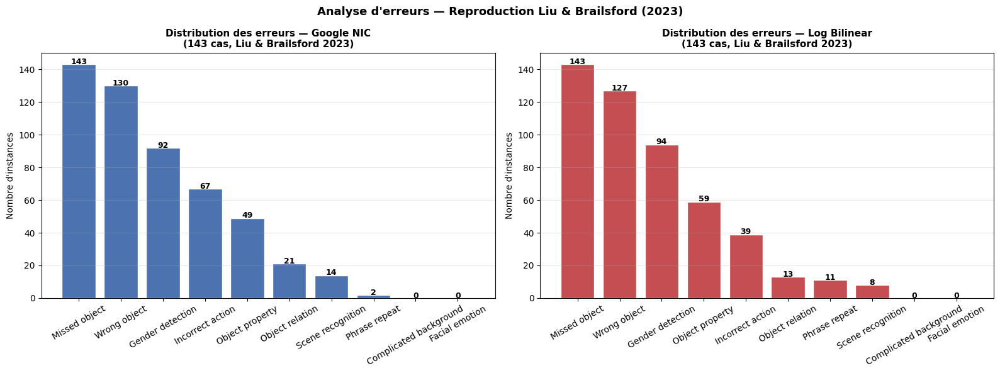

In [22]:
# ── Graphique distribution erreurs (Figure 1 du papier 2023) ─────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (counts, name, color) in zip(axes, [
    (nic_error_counts, 'Google NIC',   '#4C72B0'),
    (lb_error_counts,  'Log Bilinear', '#C44E52')
]):
    sorted_counts = dict(sorted(counts.items(), key=lambda x: x[1], reverse=True))
    bars = ax.bar(sorted_counts.keys(), sorted_counts.values(),
                  color=color, edgecolor='white')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.1,
                str(int(bar.get_height())),
                ha='center', fontsize=9, fontweight='bold')
    ax.set_title(f'Distribution des erreurs — {name}\n(143 cas, Liu & Brailsford 2023)',
                 fontsize=11, fontweight='bold')
    ax.set_ylabel('Nombre d\'instances')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Analyse d\'erreurs — Reproduction Liu & Brailsford (2023)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/error_distribution_2023.png', dpi=150)
plt.show()

Section B — Analyse automatique des noms/verbes incorrects


Analyse nouns/verbs NIC…
Analyse nouns/verbs Log Bilinear…


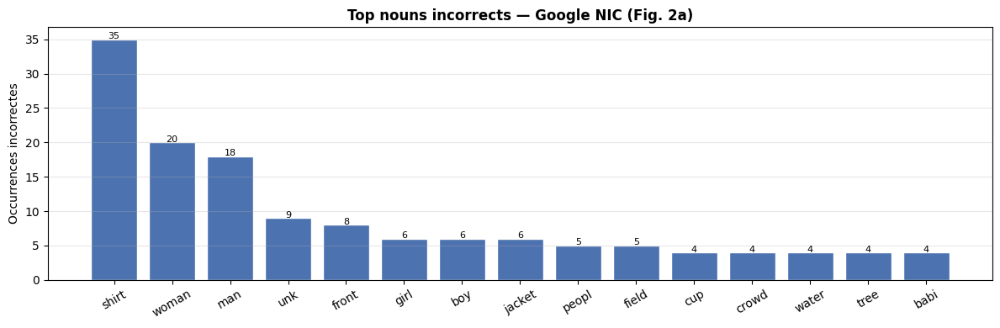

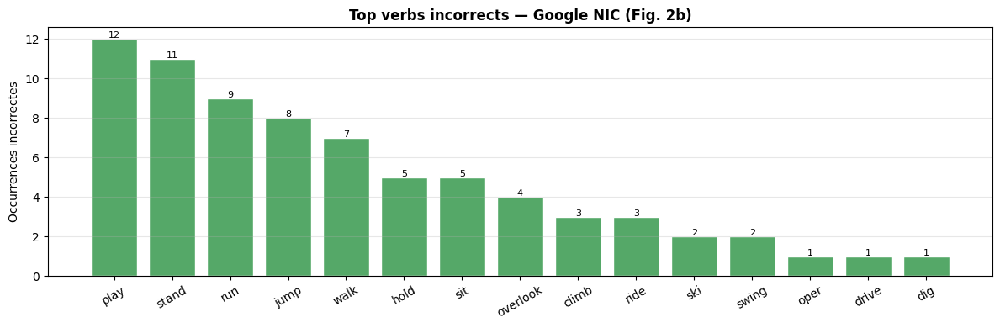

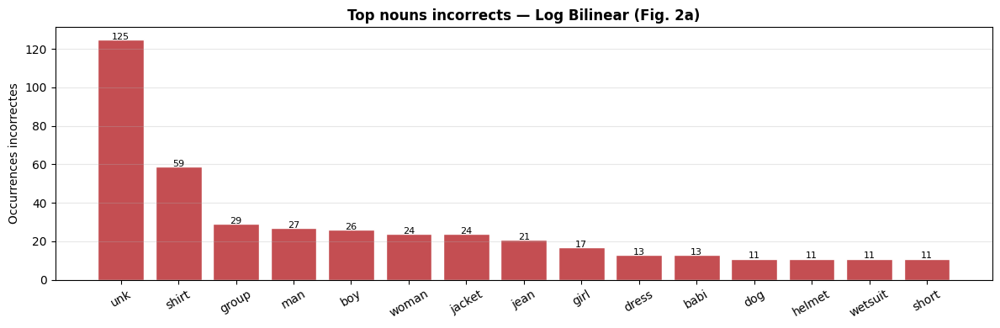

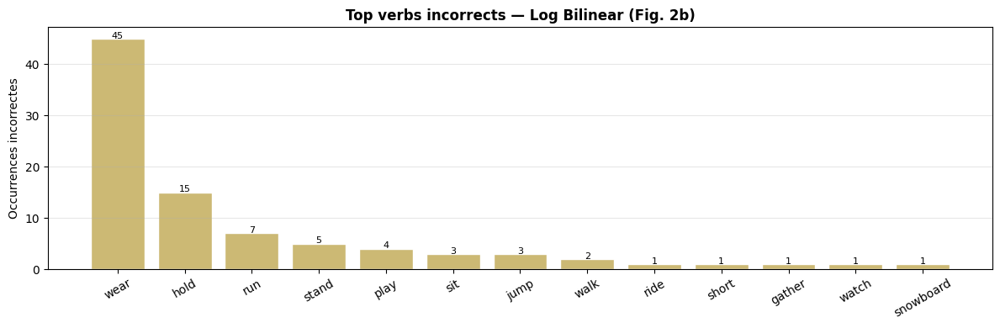

In [23]:
# ════════════════════════════════════════════════════════════════════════════
#  ARTICLE 2023 — PARTIE 2
#  Analyse automatique : nouns/verbs incorrects (Figures 2a, 2b du papier)
# ════════════════════════════════════════════════════════════════════════════

from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def extract_nouns_verbs(caption):
    """Extrait nouns et verbs avec spaCy."""
    doc   = nlp(caption)
    nouns = [stemmer.stem(t.text) for t in doc if t.pos_ == 'NOUN']
    verbs = [stemmer.stem(t.text) for t in doc if t.pos_ == 'VERB']
    return nouns, verbs


def automatic_noun_verb_analysis(model, test_refs, image_features, vocab,
                                  n_samples=143, device=DEVICE):
    """
    Reproduit la Section 3.2 de Liu & Brailsford (2023).
    Trouve les nouns/verbs présents dans la prédiction
    mais ABSENTS de toutes les références.
    """
    model.eval()
    incorrect_nouns = Counter()
    incorrect_verbs = Counter()

    for img_name in list(test_refs.keys())[:n_samples]:
        feat = image_features.get(img_name)
        if feat is None:
            continue

        with torch.no_grad():
            pred = model.generate(feat.to(device), vocab)

        pred_nouns, pred_verbs = extract_nouns_verbs(pred)

        # Tous les nouns/verbs des références (stemmed)
        ref_nouns_all = set()
        ref_verbs_all = set()
        for ref in test_refs[img_name]:
            rn, rv = extract_nouns_verbs(' '.join(ref))
            ref_nouns_all.update(rn)
            ref_verbs_all.update(rv)

        # Incorrects = dans pred mais pas dans refs
        for n in pred_nouns:
            if n not in ref_nouns_all:
                incorrect_nouns[n] += 1
        for v in pred_verbs:
            if v not in ref_verbs_all:
                incorrect_verbs[v] += 1

    return incorrect_nouns, incorrect_verbs


print('Analyse nouns/verbs NIC…')
nic_inc_nouns, nic_inc_verbs = automatic_noun_verb_analysis(
    nic_model, test_refs, image_features, vocab
)

print('Analyse nouns/verbs Log Bilinear…')
lb_inc_nouns, lb_inc_verbs = automatic_noun_verb_analysis(
    lb_model, test_refs, image_features, vocab
)

# ── Figures 2a et 2b du papier 2023 ─────────────────────────────────────────
def plot_top_incorrect(counter, title, color, top_n=15, save_name='plot'):
    top  = counter.most_common(top_n)
    keys = [k for k, _ in top]
    vals = [v for _, v in top]

    fig, ax = plt.subplots(figsize=(12, 4))
    bars = ax.bar(keys, vals, color=color, edgecolor='white')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.05,
                str(int(bar.get_height())),
                ha='center', fontsize=8)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Occurrences incorrectes')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/{save_name}.png', dpi=150)
    plt.show()

plot_top_incorrect(nic_inc_nouns,  'Top nouns incorrects — Google NIC (Fig. 2a)',
                   '#4C72B0', save_name='nic_incorrect_nouns')
plot_top_incorrect(nic_inc_verbs,  'Top verbs incorrects — Google NIC (Fig. 2b)',
                   '#55A868', save_name='nic_incorrect_verbs')
plot_top_incorrect(lb_inc_nouns,   'Top nouns incorrects — Log Bilinear (Fig. 2a)',
                   '#C44E52', save_name='lb_incorrect_nouns')
plot_top_incorrect(lb_inc_verbs,   'Top verbs incorrects — Log Bilinear (Fig. 2b)',
                   '#CCB974', save_name='lb_incorrect_verbs')

In [24]:
# ════════════════════════════════════════════════════════════════════════════
#  YOLO — Détection d'objets pour générer les labels Si
# ════════════════════════════════════════════════════════════════════════════

!pip install -q ultralytics

from ultralytics import YOLO
from PIL import Image

# Charger YOLOv8 nano (le plus léger)
yolo_model = YOLO('yolov8n.pt')
print('YOLOv8 chargé.')


def get_yolo_labels(img_path, yolo_model, conf_threshold=0.3, max_labels=5):
    """
    Détecte les objets dans une image avec YOLO.
    Retourne une liste de noms d'objets (labels Si).
    """
    results = yolo_model(str(img_path), verbose=False, conf=conf_threshold)
    labels  = []
    for result in results:
        for cls_id in result.boxes.cls.cpu().numpy():
            label = result.names[int(cls_id)].lower()
            if label not in labels:
                labels.append(label)
        if len(labels) >= max_labels:
            break
    return labels[:max_labels]


# ── Test sur une image ────────────────────────────────────────────────────────
sample_img = IMAGE_DIR / list(test_refs.keys())[0]
sample_labels = get_yolo_labels(sample_img, yolo_model)
print(f'Image : {sample_img.name}')
print(f'Labels YOLO : {sample_labels}')


# ── Cache YOLO pour les images de test ───────────────────────────────────────
YOLO_CACHE = Path('/kaggle/working/yolo_labels.pt')

def cache_yolo_labels(test_refs, image_dir, yolo_model, cache_path):
    if cache_path.exists():
        print('Chargement cache YOLO…')
        return torch.load(cache_path)

    yolo_labels = {}
    img_names   = list(test_refs.keys())

    for i, img_name in enumerate(img_names):
        img_path = image_dir / img_name
        if not img_path.exists():
            yolo_labels[img_name] = []
            continue
        try:
            yolo_labels[img_name] = get_yolo_labels(img_path, yolo_model)
        except Exception:
            yolo_labels[img_name] = []

        if i % 100 == 0:
            print(f'  YOLO traité {i}/{len(img_names)}…')

    torch.save(yolo_labels, cache_path)
    print(f'Labels YOLO sauvegardés → {cache_path}')
    return yolo_labels


print('Extraction labels YOLO (test set)…')
yolo_labels_cache = cache_yolo_labels(
    test_refs, IMAGE_DIR, yolo_model, YOLO_CACHE
)

# Aperçu
print('\n── Aperçu labels YOLO ──')
for img_name in list(test_refs.keys())[:5]:
    print(f'  {img_name[:30]} → {yolo_labels_cache.get(img_name, [])}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 19.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
YOLOv8 chargé.
Image : 1007129816_e794419615.jpg
Labels YOLO : ['person']
Extraction labels YOLO (test set)…
  YOLO traité 0/1000…
  YOLO traité 100/1000…
  YOLO traité 200/1000…
  YOLO traité 300/1000…
  YOLO traité 400/1000…
  YOLO traité 500/1000…
  YOLO traité 600/1000…
  YOLO traité 700/1000…
  YOLO traité 800/1000…
  YOLO traité 900/1000…
Labels YOLO sauvegardés → /kaggle/working/yolo_labels.pt

── Aperçu labels YOLO ──
  1007129816_e794419615.jpg → ['person']
  1015584366_dfcec3c85a.jpg → ['dog']
  1022454332_6af2c1449a.jpg → ['person']
  1082379191_ec1e53f996.jpg → ['person', 'bench']
  1107246521

Section C — Framework de correction de captions (post-processing)


In [25]:
# ════════════════════════════════════════════════════════════════════════════
#  ARTICLE 2023 — PARTIE 3
#  Framework de correction (Figure 4 + Algorithm 1 du papier)
# ════════════════════════════════════════════════════════════════════════════

# !pip install -q transformers
from transformers import GPT2LMHeadModel, GPT2Tokenizer

gpt2_tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
gpt2_model     = GPT2LMHeadModel.from_pretrained('gpt2').to(DEVICE)
gpt2_model.eval()
print('GPT-2 chargé.')


def compute_sentence_score(sentence, tokenizer, lm_model, device=DEVICE):
    """
    Calcule le score de vraisemblance d'une phrase avec GPT-2.
    Score élevé = phrase plus naturelle.
    Reproduit la Table 1 de Liu & Brailsford (2023).
    """
    inputs = tokenizer(sentence, return_tensors='pt').to(device)
    with torch.no_grad():
        outputs = lm_model(**inputs, labels=inputs['input_ids'])
    # Perplexité inverse → score plus élevé = meilleure phrase
    loss  = outputs.loss.item()
    score = np.exp(-loss) * 1000
    return round(score, 2)


def extract_nouns_verbs_set(caption):
    """Retourne deux sets : nouns et verbs d'une caption."""
    doc   = nlp(caption)
    nouns = {t.text.lower() for t in doc if t.pos_ == 'NOUN'}
    verbs = {t.text.lower() for t in doc if t.pos_ == 'VERB'}
    return nouns, verbs


def correct_caption(sat_caption, image_labels, tokenizer, lm_model, device=DEVICE):
    """
    Algorithm 1 du papier 2023 — Correct The Caption.

    sat_caption   : caption générée par le modèle (str)
    image_labels  : mots détectés dans l'image par VGG/YOLO (list of str)

    Retourne : (meilleure_caption, score, toutes_les_candidates)
    """
    # Sc = nouns + verbs de la caption générée
    sc_nouns, sc_verbs = extract_nouns_verbs_set(sat_caption)
    Sc = sc_nouns | sc_verbs

    # Si = labels de l'image (détectés par VGG/YOLO)
    Si = set(image_labels)

    # Score de la caption originale
    score_original = compute_sentence_score(sat_caption, tokenizer, lm_model, device)
    candidates     = [(sat_caption, score_original)]

    # Pour chaque mot de Sc, essayer de le remplacer par chaque mot de Si
    tokens = sat_caption.split()
    for c in list(Sc):
        for i_word in Si:
            new_tokens = [i_word if t.lower() == c else t for t in tokens]
            new_cap    = ' '.join(new_tokens)
            if new_cap != sat_caption:
                new_score = compute_sentence_score(new_cap, tokenizer, lm_model, device)
                candidates.append((new_cap, new_score))

    # Retourner la caption avec le score le plus élevé
    best_caption, best_score = max(candidates, key=lambda x: x[1])
    return best_caption, best_score, candidates


# ── Remplacer la simulation dans demo_correction ─────────────────────────────
def demo_correction_yolo(model, model_name, test_refs, image_features,
                         vocab, yolo_labels_cache, n=5, device=DEVICE):
    model.eval()
    img_names = list(test_refs.keys())[:n]

    print(f'\n{"="*70}')
    print(f'  Framework correction YOLO — {model_name}')
    print(f'{"="*70}')

    for img_name in img_names:
        feat = image_features.get(img_name)
        if feat is None:
            continue
        with torch.no_grad():
            pred = model.generate(feat.to(device), vocab)

        # Labels YOLO réels
        image_labels = yolo_labels_cache.get(img_name, [])

        # Fallback si YOLO n'a rien détecté
        if not image_labels:
            ref_nouns = set()
            for ref in test_refs[img_name]:
                n_set, _ = extract_nouns_verbs_set(' '.join(ref))
                ref_nouns.update(n_set)
            image_labels = list(ref_nouns)[:5]
            source = 'simulé'
        else:
            source = 'YOLO'

        best_cap, best_score, all_candidates = correct_caption(
            pred, image_labels,
            gpt2_tokenizer, gpt2_model, device
        )
        orig_score = compute_sentence_score(
            pred, gpt2_tokenizer, gpt2_model, device
        )

        print(f'\nImage      : {img_name}')
        print(f'Référence  : {" ".join(test_refs[img_name][0])}')
        print(f'Original   : {pred}  [score={orig_score}]')
        print(f'Corrigée   : {best_cap}  [score={best_score}]')
        print(f'Labels Si  : {image_labels}  (source: {source})')
        print(f'Top 3 candidates :')
        for cap, sc in sorted(all_candidates, key=lambda x: x[1], reverse=True)[:3]:
            print(f'  [{sc:.1f}] {cap}')


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 chargé.


`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.



  Framework correction YOLO — Google_NIC

Image      : 1007129816_e794419615.jpg
Référence  : a man in an orange hat starring at something .
Original   [14.22]: a man wearing a hat and a hat .
Corrigée   [14.22]: a man wearing a hat and a hat .
Labels Si  : ['person']  (source: YOLO)
Top 3 :
  [14.2] a man wearing a hat and a hat .
  [10.7] a person wearing a hat and a hat .
  [4.6] a man wearing a person and a person .

Image      : 1015584366_dfcec3c85a.jpg
Référence  : a black dog leaps over a log .
Original   [2.78]: a black dog jumps over a log .
Corrigée   [4.69]: a black dog jumps over a dog .
Labels Si  : ['dog']  (source: YOLO)
Top 3 :
  [4.7] a black dog jumps over a dog .
  [2.8] a black dog jumps over a log .
  [1.3] a black dog dog over a log .

Image      : 1022454332_6af2c1449a.jpg
Référence  : a child and a woman are at waters edge in a big city .
Original   [6.97]: a girl is jumping into the water .
Corrigée   [6.97]: a girl is jumping into the water .
Labels Si  : ['

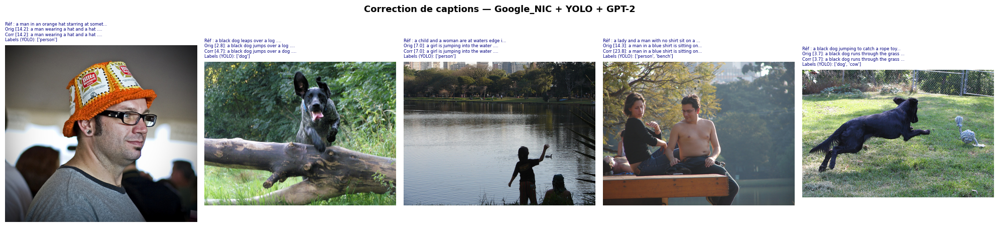


  Framework correction YOLO — Log_Bilinear

Image      : 1007129816_e794419615.jpg
Référence  : a man in an orange hat starring at something .
Original   [3.49]: a man and a hat is a <UNK> .
Corrigée   [3.95]: a man and a person is a <UNK> .
Labels Si  : ['person']  (source: YOLO)
Top 3 :
  [4.0] a man and a person is a <UNK> .
  [3.5] a man and a hat is a <UNK> .
  [3.1] a person and a hat is a <UNK> .

Image      : 1015584366_dfcec3c85a.jpg
Référence  : a black dog leaps over a log .
Original   [6.70]: a black and white dog jumping over a lake .
Corrigée   [6.70]: a black and white dog jumping over a lake .
Labels Si  : ['dog']  (source: YOLO)
Top 3 :
  [6.7] a black and white dog jumping over a lake .
  [6.2] a black and white dog jumping over a dog .
  [4.0] a black and white dog dog over a lake .

Image      : 1022454332_6af2c1449a.jpg
Référence  : a child and a woman are at waters edge in a big city .
Original   [7.13]: a boy in a red shirt and a pants on a lake .
Corrigée   [7.

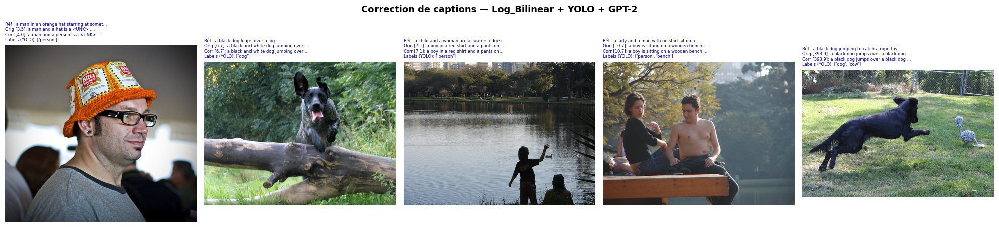

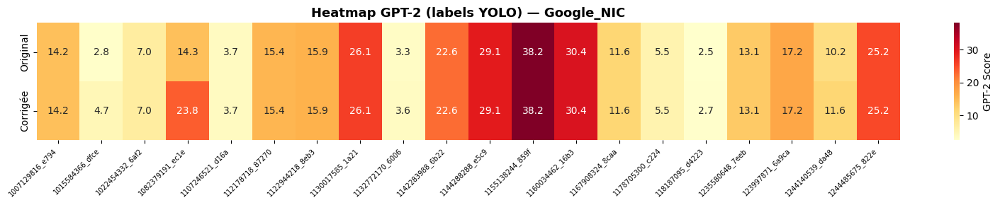

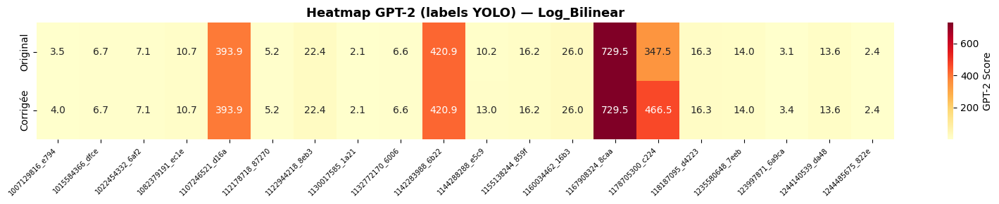

In [26]:
import seaborn as sns
from PIL import Image

def plot_correction_heatmap_yolo(model, model_name, test_refs, image_features,
                                  vocab, yolo_labels_cache, n=20, device=DEVICE):
    model.eval()
    img_names   = list(test_refs.keys())[:n]
    orig_scores = []
    corr_scores = []
    labels      = []

    for img_name in img_names:
        feat = image_features.get(img_name)
        if feat is None:
            continue
        with torch.no_grad():
            pred = model.generate(feat.to(device), vocab)

        image_labels = yolo_labels_cache.get(img_name, [])
        if not image_labels:
            ref_nouns = set()
            for ref in test_refs[img_name]:
                n_set, _ = extract_nouns_verbs_set(' '.join(ref))
                ref_nouns.update(n_set)
            image_labels = list(ref_nouns)[:5]

        best_cap, best_score, _ = correct_caption(
            pred, image_labels, gpt2_tokenizer, gpt2_model, device
        )
        orig_score = compute_sentence_score(
            pred, gpt2_tokenizer, gpt2_model, device
        )
        orig_scores.append(orig_score)
        corr_scores.append(best_score)
        labels.append(img_name[:15])

    # ── Heatmap ──────────────────────────────────────────────────────────────
    data = np.array([orig_scores, corr_scores])
    fig, ax = plt.subplots(figsize=(16, 3))
    sns.heatmap(data, annot=True, fmt='.1f', cmap='YlOrRd',
                xticklabels=labels,
                yticklabels=['Original', 'Corrigée'],
                ax=ax, cbar_kws={'label': 'GPT-2 Score'})
    ax.set_title(f'Heatmap GPT-2 (labels YOLO) — {model_name}',
                 fontsize=13, fontweight='bold')
    plt.xticks(rotation=45, ha='right', fontsize=7)
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/heatmap_yolo_{model_name}.png', dpi=150)
    plt.show()


def demo_correction_yolo_with_images(model, model_name, test_refs, image_features,
                                      vocab, yolo_labels_cache, image_dir,
                                      n=5, device=DEVICE):
    """
    Affiche les images + captions originale/corrigée côte à côte.
    """
    model.eval()
    img_names = list(test_refs.keys())[:n]

    print(f'\n{"="*70}')
    print(f'  Framework correction YOLO — {model_name}')
    print(f'{"="*70}')

    fig, axes = plt.subplots(1, n, figsize=(4*n, 5))
    if n == 1:
        axes = [axes]

    for ax, img_name in zip(axes, img_names):
        feat = image_features.get(img_name)
        if feat is None:
            continue

        with torch.no_grad():
            pred = model.generate(feat.to(device), vocab)

        # Labels YOLO avec fallback
        image_labels = yolo_labels_cache.get(img_name, [])
        source = 'YOLO'
        if not image_labels:
            ref_nouns = set()
            for ref in test_refs[img_name]:
                n_set, _ = extract_nouns_verbs_set(' '.join(ref))
                ref_nouns.update(n_set)
            image_labels = list(ref_nouns)[:5]
            source = 'simulé'

        best_cap, best_score, all_candidates = correct_caption(
            pred, image_labels, gpt2_tokenizer, gpt2_model, device
        )
        orig_score = compute_sentence_score(
            pred, gpt2_tokenizer, gpt2_model, device
        )

        # ── Afficher l'image ─────────────────────────────────────────────────
        img_path = image_dir / img_name
        if img_path.exists():
            img = Image.open(img_path).convert('RGB')
            ax.imshow(img)

        ref_text  = ' '.join(test_refs[img_name][0])
        title = (f"Réf : {ref_text[:40]}...\n"
                 f"Orig [{orig_score:.1f}]: {pred[:35]}...\n"
                 f"Corr [{best_score:.1f}]: {best_cap[:35]}...\n"
                 f"Labels ({source}): {image_labels}")
        ax.set_title(title, fontsize=6, color='navy', loc='left')
        ax.axis('off')

        # ── Log console ──────────────────────────────────────────────────────
        print(f'\nImage      : ', end='')
        ax_img = Image.open(img_path) if img_path.exists() else None
        print(img_name)
        print(f'Référence  : {ref_text}')
        print(f'Original   [{orig_score:.2f}]: {pred}')
        print(f'Corrigée   [{best_score:.2f}]: {best_cap}')
        print(f'Labels Si  : {image_labels}  (source: {source})')
        print(f'Top 3 :')
        for cap, sc in sorted(all_candidates, key=lambda x: x[1], reverse=True)[:3]:
            print(f'  [{sc:.1f}] {cap}')

    plt.suptitle(f'Correction de captions — {model_name} + YOLO + GPT-2',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/demo_correction_{model_name}.png', dpi=150)
    plt.show()


# ── Appels finaux pour les DEUX modèles ──────────────────────────────────────
demo_correction_yolo_with_images(nic_model, 'Google_NIC',
                                  test_refs, image_features, vocab,
                                  yolo_labels_cache, IMAGE_DIR, n=5)

demo_correction_yolo_with_images(lb_model, 'Log_Bilinear',
                                  test_refs, image_features, vocab,
                                  yolo_labels_cache, IMAGE_DIR, n=5)

plot_correction_heatmap_yolo(nic_model, 'Google_NIC',
                              test_refs, image_features, vocab, yolo_labels_cache)

plot_correction_heatmap_yolo(lb_model,  'Log_Bilinear',
                              test_refs, image_features, vocab, yolo_labels_cache)

Section D — Typed Dependency Parser

In [27]:
# ════════════════════════════════════════════════════════════════════════════
#  ARTICLE 2023 — PARTIE 4
#  Typed Dependency Parser (Section 4.2 du papier)
# ════════════════════════════════════════════════════════════════════════════

def to_typed_dependency(caption):
    """
    Transforme une caption en mots de dépendance typée.
    Exemple :
      'A man is jumping'
      → 'det-man-a nsubj-jump-man aux-jump-is root-jump'

    Reproduit la transformation de la Figure 7 du papier 2023.
    """
    doc    = nlp(caption)
    dep_words = []
    for token in doc:
        if token.dep_ != 'ROOT':
            dep_word = f"{token.dep_}-{token.head.lemma_}-{token.lemma_}"
        else:
            dep_word = f"root-{token.lemma_}"
        dep_words.append(dep_word)
    return ' '.join(dep_words)


# ── Démonstration ────────────────────────────────────────────────────────────
examples = [
    'A man is jumping over a fence',
    'A woman is sitting on a bench',
    'A dog is running in a field',
    'Two children are playing with a ball',
]

print('══ Exemples de transformation Typed Dependency ══\n')
for cap in examples:
    dep = to_typed_dependency(cap)
    print(f'Original   : {cap}')
    print(f'Transformée: {dep}')
    print()

══ Exemples de transformation Typed Dependency ══

Original   : A man is jumping over a fence
Transformée: det-man-a nsubj-jump-man aux-jump-be root-jump prep-jump-over det-fence-a pobj-over-fence

Original   : A woman is sitting on a bench
Transformée: det-woman-a nsubj-sit-woman aux-sit-be root-sit prep-sit-on det-bench-a pobj-on-bench

Original   : A dog is running in a field
Transformée: det-dog-a nsubj-run-dog aux-run-be root-run prep-run-in det-field-a pobj-in-field

Original   : Two children are playing with a ball
Transformée: nummod-child-two nsubj-play-child aux-play-be root-play prep-play-with det-ball-a pobj-with-ball



In [28]:
# ── Transformation de tout le dataset train ──────────────────────────────────
def build_typed_dependency_dataset(df):
    """
    Transforme toutes les captions du dataset en typed-dependency words.
    Reproduit l'expérience de la Section 4.2 du papier 2023.
    """
    df_new = df.copy()
    df_new['caption_original']   = df_new['caption']
    df_new['caption_dependency'] = df_new['caption'].apply(to_typed_dependency)
    return df_new

train_df_dep = build_typed_dependency_dataset(train_df)
val_df_dep   = build_typed_dependency_dataset(val_df)

# Statistiques vocabulaire (comme dans le papier)
vocab_original   = set(w for cap in train_df['caption'] for w in cap.split())
vocab_dependency = set(w for cap in train_df_dep['caption_dependency'] for w in cap.split())

print(f'Taille vocabulaire original   : {len(vocab_original):,}')
print(f'Taille vocabulaire dependency : {len(vocab_dependency):,}')
print(f'(Papier 2023 : 28,417 → 317,119)')

# Aperçu
print('\n── Aperçu des transformations ──')
print(train_df_dep[['caption_original', 'caption_dependency']].head(5).to_string())

Taille vocabulaire original   : 7,774
Taille vocabulaire dependency : 60,560
(Papier 2023 : 28,417 → 317,119)

── Aperçu des transformations ──
                                                           caption_original                                                                                                                                                                                                                                 caption_dependency
0  a child in a pink dress is climbing up a set of stairs in an entry way .  det-child-a nsubj-climb-child prep-child-in det-dress-a amod-dress-pink pobj-in-dress aux-climb-be root-climb prt-climb-up det-set-a dobj-climb-set prep-set-of pobj-of-stair prep-set-in det-way-an compound-way-entry pobj-in-way punct-climb-.
1                                     a girl going into a wooden building .                                                                                                                                  det-girl-a ro

Taille vocabulaire : 21807
Vocabulaire dependency : 21807
Paramètres NIC-Dependency : 22,541,871

  NIC_Dependency  |  max 50 epochs  |  patience=7  |  lr=0.0004
[NIC_Dependency] Ep 001/50 | Train Loss: 6.7963  Acc: 0.1785 | Val Loss: 5.4937  Acc: 0.2704 | 70.9s | ✔ best saved
[NIC_Dependency] Ep 002/50 | Train Loss: 5.6924  Acc: 0.2427 | Val Loss: 4.7885  Acc: 0.3049 | 70.8s | ✔ best saved
[NIC_Dependency] Ep 003/50 | Train Loss: 5.0999  Acc: 0.2726 | Val Loss: 4.3723  Acc: 0.3307 | 70.9s | ✔ best saved
[NIC_Dependency] Ep 004/50 | Train Loss: 4.6777  Acc: 0.2932 | Val Loss: 4.1042  Acc: 0.3465 | 71.0s | ✔ best saved
[NIC_Dependency] Ep 005/50 | Train Loss: 4.3528  Acc: 0.3095 | Val Loss: 3.8966  Acc: 0.3587 | 70.9s | ✔ best saved
[NIC_Dependency] Ep 006/50 | Train Loss: 4.0922  Acc: 0.3230 | Val Loss: 3.7576  Acc: 0.3666 | 70.9s | ✔ best saved
[NIC_Dependency] Ep 007/50 | Train Loss: 3.8758  Acc: 0.3345 | Val Loss: 3.6458  Acc: 0.3760 | 70.9s | ✔ best saved
[NIC_Dependency] Ep 008/50

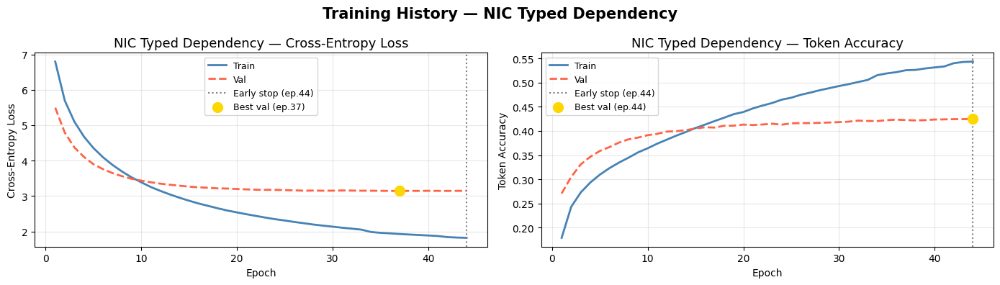

In [29]:
# ── Réentraîner NIC sur les captions typed-dependency ────────────────────────

# Préparer les DataFrames correctement — garder UNIQUEMENT les colonnes nécessaires
train_df_dep_clean = train_df_dep[['image', 'caption_dependency']].rename(
    columns={'caption_dependency': 'caption'}
).reset_index(drop=True)

val_df_dep_clean = val_df_dep[['image', 'caption_dependency']].rename(
    columns={'caption_dependency': 'caption'}
).reset_index(drop=True)

# Nouveau vocabulaire sur les captions transformées
vocab_dep = Vocabulary(min_freq=2)
vocab_dep.build(train_df_dep_clean['caption'].tolist())
print(f'Vocabulaire dependency : {len(vocab_dep)}')

# Datasets avec captions transformées
train_set_dep = Flickr8kDataset(train_df_dep_clean, image_features, vocab_dep)
val_set_dep   = Flickr8kDataset(val_df_dep_clean,   image_features, vocab_dep)

train_loader_dep = DataLoader(train_set_dep, batch_size=BATCH,
                               shuffle=True,  num_workers=2, pin_memory=True)
val_loader_dep   = DataLoader(val_set_dep,   batch_size=BATCH,
                               shuffle=False, num_workers=2, pin_memory=True)

# Nouveau modèle NIC avec le vocabulaire dependency
nic_dep_model = NIC_Decoder(
    vocab_size=len(vocab_dep),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    feat_dim=FEAT_DIM
).to(DEVICE)

print(f'Paramètres NIC-Dependency : {sum(p.numel() for p in nic_dep_model.parameters()):,}')

# Entraînement
nic_dep_history, nic_dep_stopped = training_loop(
    nic_dep_model, train_loader_dep, val_loader_dep,
    epochs=50, lr=4e-4, label='NIC_Dependency',
    patience=7, min_delta=1e-4
)

plot_history(nic_dep_history, 'NIC Typed Dependency', stopped_at=nic_dep_stopped)

In [30]:
# ── Comparaison finale : NIC original vs NIC dependency ─────────────────────
print('\n══ Exemple de captions générées ══')
print('(NIC original vs NIC typed-dependency)\n')

for img_name in list(test_refs.keys())[:5]:
    feat = image_features.get(img_name)
    if feat is None:
        continue

    with torch.no_grad():
        cap_original   = nic_model.generate(feat.to(DEVICE), vocab)
        cap_dependency = nic_dep_model.generate(feat.to(DEVICE), vocab_dep)

    print(f'Image      : {img_name}')
    print(f'Référence  : {" ".join(test_refs[img_name][0])}')
    print(f'NIC        : {cap_original}')
    print(f'NIC-Dep    : {cap_dependency}')
    print()


══ Exemple de captions générées ══
(NIC original vs NIC typed-dependency)

Image      : 1007129816_e794419615.jpg
Référence  : a man in an orange hat starring at something .
NIC        : a man wearing a hat and a hat .
NIC-Dep    : det-man-a root-man acl-man-wear det-hat-a amod-hat-black dobj-wear-hat cc-hat-and conj-hat-sunglass punct-sunglass-, <UNK> <UNK> punct-man-.

Image      : 1015584366_dfcec3c85a.jpg
Référence  : a black dog leaps over a log .
NIC        : a black dog jumps over a log .
NIC-Dep    : det-dog-a amod-dog-black root-dog acl-dog-run prep-run-through pobj-through-water prep-run-with det-stick-a pobj-with-stick prep-stick-in poss-mouth-its pobj-in-mouth punct-dog-.

Image      : 1022454332_6af2c1449a.jpg
Référence  : a child and a woman are at waters edge in a big city .
NIC        : a girl is jumping into the water .
NIC-Dep    : det-boy-a root-boy prep-boy-in det-shirt-a amod-shirt-red pobj-in-shirt cc-boy-and amod-jean-blue conj-shirt-jean <UNK> <UNK> <UNK> <UNK>